# 04 Clustering: a typology of Russian monotowns

**Goal:** group monotowns into types by their demographic and economic trajectory, then see where Slantsy (item 109 in Order 469-р) fits.

**Data:** `data/processed/features.csv` from notebook 03: 247 monotowns. Only towns with all five clustering variables are clustered; missing values are not imputed.

**Clustering variables**

| variable | meaning | years |
|---|---|---|
| `pop_change_23_25` | population change, % | 2023 to 2025 |
| `net_mig_per_1000` | average yearly net migration per 1,000 residents | 2021-2023 |
| `wage_rel` | average wage relative to the regional median of districts and okrugs | 2025 |
| `jobs_per_1000` | employees of large and medium organisations per 1,000 residents | 2025 |
| `job_change_pct` | change in the number of those employees, % | 2017 to 2025 |

The industry share (mining + manufacturing) is not used to build clusters: Rosstat hides the data of dominant employers for confidentiality, so it is only a lower bound. It is used later to describe the clusters.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"  # avoids a k-means memory-leak warning on Windows

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [2]:
# oktmo codes stay text (some start with 0)
features = pd.read_csv(
    "../data/processed/features.csv",
    dtype={"oktmo": str, "wage_key": str},
)

POP_OLD, POP_NEW = "pop_change_pct", "pop_change_23_25"
OTHER_VARS = ["net_mig_per_1000", "wage_rel", "jobs_per_1000", "job_change_pct"]
SLANTSY = 109

print("All monotowns:", features.shape)

All monotowns: (247, 36)


## Choosing the population variable

The 2021 census reset Rosstat's population estimates, so population change 2017-2025 mixes real change with the census correction (see notebook 03). Population change 2023-2025 is shorter but on one census basis. As a check, both are compared with net migration, which comes from registrations and is not affected by the census reset.

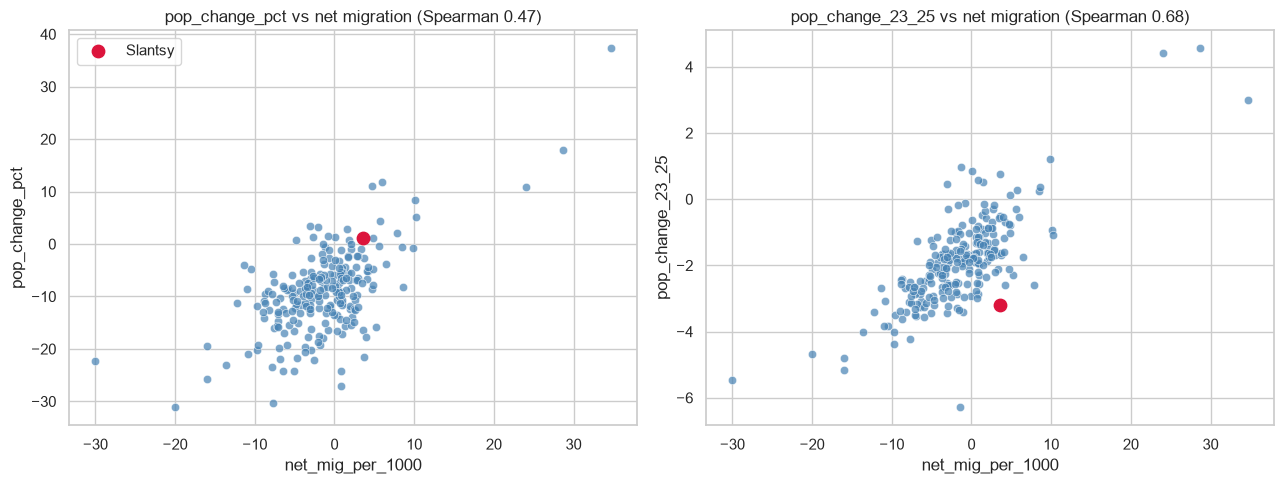

Towns with each variable: 234 vs 239


In [3]:
both = features.dropna(subset=[POP_OLD, POP_NEW, "net_mig_per_1000"])
slantsy = both[both["number"] == SLANTSY]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, var in zip(axes, [POP_OLD, POP_NEW]):
    sns.scatterplot(data=both, x="net_mig_per_1000", y=var, ax=ax, color="steelblue", alpha=0.7)
    ax.scatter(slantsy["net_mig_per_1000"], slantsy[var], color="crimson", s=80, label="Slantsy")
    rho = both[var].corr(both["net_mig_per_1000"], method="spearman")
    ax.set_title(f"{var} vs net migration (Spearman {rho:.2f})")
axes[0].legend()
plt.tight_layout()
plt.show()

print("Towns with each variable:", features[POP_OLD].notna().sum(), "vs", features[POP_NEW].notna().sum())

In [4]:
# population change 2023-2025 replaces 2017-2025
CLUSTER_VARS = [POP_NEW] + OTHER_VARS
df = features.dropna(subset=CLUSTER_VARS).copy().reset_index(drop=True)
print("In clustering:", len(df))

# which towns entered or left compared with the old selection from notebook 03
old, new = set(features.loc[features["in_clustering"], "number"]), set(df["number"])
print("Added:  ", features.loc[features["number"].isin(new - old), ["number", "name_en"]].values.tolist())
print("Dropped:", features.loc[features["number"].isin(old - new), ["number", "name_en"]].values.tolist())

df.loc[df["number"] == SLANTSY, ["number", "name_en", "region_en", "category"] + CLUSTER_VARS]

In clustering: 232
Added:   [[9, 'Petrovsk-Zabaykalsky'], [76, 'Verkh-Usugli'], [77, 'Krasnokamensk'], [78, 'Aginskoye'], [79, 'Borzya']]
Dropped: [[243, 'Kasimov']]


,number,name_en,region_en,category,pop_change_23_25,net_mig_per_1000,wage_rel,jobs_per_1000,job_change_pct
95,109,Slantsy,Leningrad Oblast,2,-3.207783,3.54558,0.990582,138.700823,-0.55756


In [5]:
df[CLUSTER_VARS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pop_change_23_25,232.0,-1.88,1.34,-6.29,-2.66,-1.89,-1.23,4.55
net_mig_per_1000,232.0,-1.57,6.22,-30.03,-4.85,-1.42,1.46,34.72
wage_rel,232.0,1.14,0.25,0.70,0.99,1.08,1.25,2.85
jobs_per_1000,232.0,236.34,92.77,61.38,171.52,218.21,268.39,618.30
job_change_pct,232.0,-5.34,18.67,-42.42,-14.56,-8.67,-0.65,101.83


## Distributions and outliers

K-means groups towns by distance, so it is sensitive to scale and to extreme values. Before scaling, we check how each variable is distributed, which towns are extreme, and whether any two variables measure nearly the same thing (strongly correlated variables would count twice in the distance).

An outlier here is a town more than 3 standard deviations from the mean (|z| > 3).

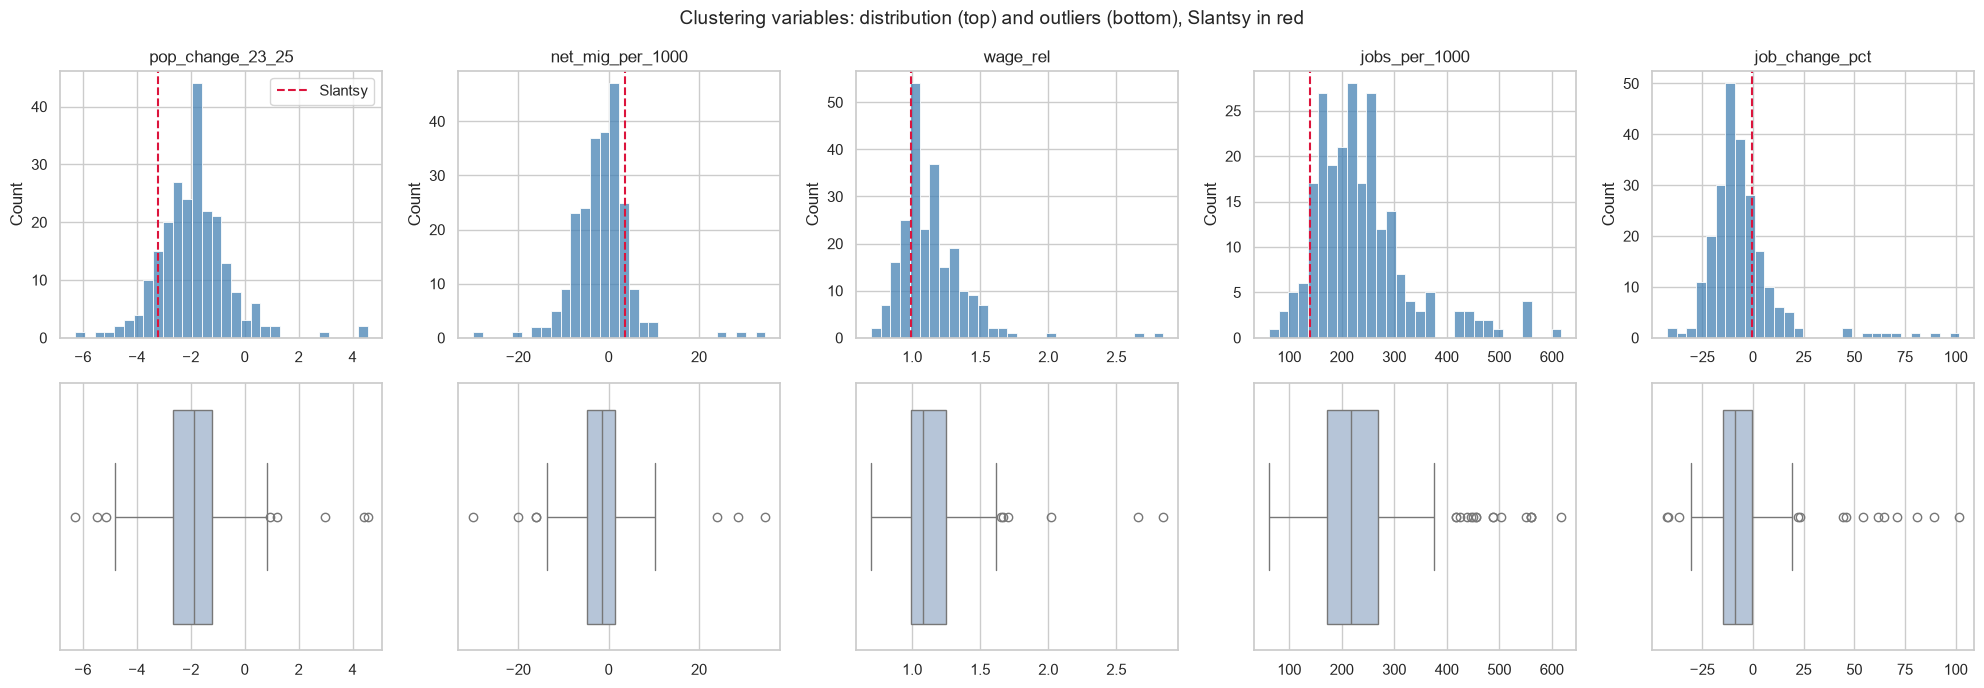

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))

for i, var in enumerate(CLUSTER_VARS):
    sns.histplot(df[var], bins=30, ax=axes[0, i], color="steelblue")
    axes[0, i].axvline(df.loc[df["number"] == SLANTSY, var].iloc[0],
                       color="crimson", linestyle="--", label="Slantsy")
    axes[0, i].set_title(var)
    axes[0, i].set_xlabel("")
    sns.boxplot(x=df[var], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_xlabel("")

axes[0, 0].legend()
plt.suptitle("Clustering variables: distribution (top) and outliers (bottom), Slantsy in red",
             fontsize=14)
plt.tight_layout()
plt.show()

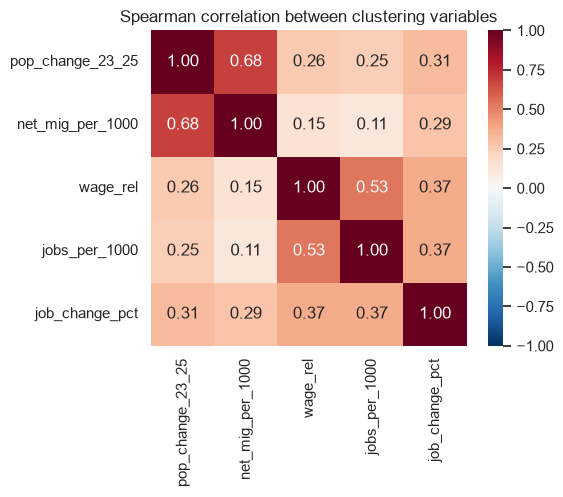

In [7]:
corr = df[CLUSTER_VARS].corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation between clustering variables")
plt.tight_layout()
plt.show()

In [8]:
# |z| > 3 on any variable
z = (df[CLUSTER_VARS] - df[CLUSTER_VARS].mean()) / df[CLUSTER_VARS].std()
outlier_mask = (z.abs() > 3).any(axis=1)

outliers = df.loc[outlier_mask, ["number", "name_en", "region_en"] + CLUSTER_VARS].copy()
outliers["extreme_on"] = z[outlier_mask].apply(
    lambda row: ", ".join(row.index[row.abs() > 3]), axis=1)

print("Towns with |z| > 3:", outlier_mask.sum())
outliers.round(2).sort_values("extreme_on")

Towns with |z| > 3: 15


,number,name_en,region_en,pop_change_23_25,net_mig_per_1000,wage_rel,jobs_per_1000,job_change_pct,extreme_on
155,181,Aleksin,Tula Oblast,-2.34,1.76,1.13,437.81,101.83,job_change_pct
211,241,Zelenodolsk,Republic of Tatarstan,-0.29,5.54,0.87,341.21,64.66,job_change_pct
223,255,Kotovsk,Tambov Oblast,-1.74,2.40,1.18,456.60,89.56,job_change_pct
99,113,Kirovsk,Murmansk Oblast,-1.89,-5.20,1.43,618.30,18.63,jobs_per_1000
131,155,Aykhal,Sakha Republic (Yakutia),0.96,-1.29,1.34,561.32,9.66,jobs_per_1000
132,156,Mirny,Sakha Republic (Yakutia),0.84,0.04,1.34,561.32,9.66,jobs_per_1000
129,153,Neryungri,Sakha Republic (Yakutia),-0.30,2.64,1.30,550.82,61.92,"jobs_per_1000, job_change_pct"
101,115,Nikel,Murmansk Oblast,-5.47,-30.03,0.99,302.86,-20.92,net_mig_per_1000
33,44,Skopin,Ryazan Oblast,-6.29,-1.41,0.90,188.59,-4.87,pop_change_23_25
148,173,Verkhnyaya Pyshma,Sverdlovsk Oblast,4.43,23.98,1.52,283.46,18.60,"pop_change_23_25, net_mig_per_1000"


## Capping outliers and scaling

The 15 extreme towns are real (defence-industry job growth, northern mining towns, growing suburbs, Nikel after the smelter closure), so they stay in the analysis. To stop them from pulling cluster centres, each variable is capped at its 2nd and 98th percentile (winsorizing): values beyond these limits are set to the limit. The original values are kept for describing the clusters.

The variables are then standardised (mean 0, standard deviation 1), because k-means measures distance and would otherwise be dominated by the variable with the largest numbers (jobs per 1,000).

In [9]:
# cap each variable at its 2nd and 98th percentile; df keeps the original values
lower = df[CLUSTER_VARS].quantile(0.02)
upper = df[CLUSTER_VARS].quantile(0.98)
X_capped = df[CLUSTER_VARS].clip(lower=lower, upper=upper, axis=1)

print("Towns capped per variable:")
print(((df[CLUSTER_VARS] < lower) | (df[CLUSTER_VARS] > upper)).sum(), "\n")

# standardise: each variable gets mean 0 and standard deviation 1
X = StandardScaler().fit_transform(X_capped)
pd.DataFrame(X, columns=CLUSTER_VARS).describe().T.round(2)

Towns capped per variable:
pop_change_23_25    10
net_mig_per_1000    10
wage_rel            10
jobs_per_1000       10
job_change_pct      10
dtype: int64 



,count,mean,std,min,25%,50%,75%,max
pop_change_23_25,232.0,-0.0,1.0,-2.26,-0.65,0.02,0.59,2.42
net_mig_per_1000,232.0,0.0,1.0,-2.39,-0.65,0.06,0.65,2.41
wage_rel,232.0,-0.0,1.0,-1.66,-0.68,-0.23,0.59,2.67
jobs_per_1000,232.0,-0.0,1.0,-1.53,-0.72,-0.20,0.37,3.24
job_change_pct,232.0,0.0,1.0,-1.38,-0.55,-0.19,0.30,4.16


## Choosing the number of clusters

K-means is run for k = 2 to 8. Two measures guide the choice:
- **Inertia** (sum of squared distances of towns to their cluster centre) always falls as k grows; the "elbow", where it stops falling steeply, suggests a reasonable k.
- **Silhouette score** (from -1 to 1) measures how much closer towns are to their own cluster than to the next one; higher is better.

Cluster sizes are checked too: a typology with clusters of two or three towns is not useful. Each run uses 50 random starts (`n_init=50`) and a fixed `random_state` so results are reproducible.

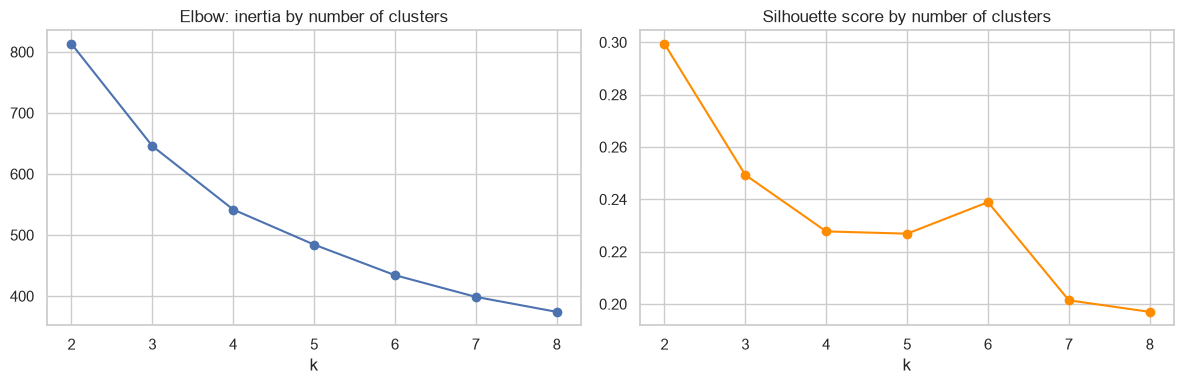

,k,inertia,silhouette,sizes
0,2,813.252,0.299,"[155, 77]"
1,3,645.852,0.249,"[124, 84, 24]"
2,4,541.800,0.228,"[77, 70, 65, 20]"
3,5,484.322,0.227,"[80, 56, 41, 37, 18]"
4,6,434.267,0.239,"[80, 56, 41, 36, 10, 9]"
5,7,398.697,0.201,"[63, 43, 42, 37, 28, 10, 9]"
6,8,374.135,0.197,"[63, 43, 32, 29, 28, 19, 9, 9]"


In [10]:
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    sizes = sorted(np.bincount(km.labels_), reverse=True)
    results.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X, km.labels_), "sizes": sizes})
results = pd.DataFrame(results)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results["k"], results["inertia"], marker="o")
axes[0].set_title("Elbow: inertia by number of clusters")
axes[1].plot(results["k"], results["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Silhouette score by number of clusters")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

results.round(3)

## Final clustering: six types

k = 6 is chosen because:
- the four large clusters are nearly identical at k = 5 and k = 6, so they reflect stable structure;
- k = 4 merges two groups with similar wages and jobs but opposite migration (towns that keep their people vs towns that lose them);
- k = 5 mixes high-employment northern towns with recent boom towns, which k = 6 separates;
- k = 6 has the highest silhouette after k = 2 (0.24), and the elbow flattens after it, while k = 7 fragments.

A silhouette of 0.24 means the types overlap: they describe tendencies rather than sharp boundaries. The two smallest types rest on 9-10 towns each.

In [11]:
K = 6
km = KMeans(n_clusters=K, n_init=50, random_state=42).fit(X)
df["cluster"] = km.labels_
df["cluster"].value_counts().sort_index()

cluster
0    80
1    36
2    56
3    41
4    10
5     9
Name: count, dtype: int64

## From clusters to types

K-means only returns six numbered groups of similar towns; it does not say what they mean. The meaning comes from reading each cluster's centre, the "average town" of the group: on which variables is it above or below the average monotown?

The heatmap shows the centres in standardised units: 0 is the average of all 232 towns, +1 is one standard deviation above it, -1 one below. Red means above average, blue below. Each type is named after its most distinctive pattern, and the medians and member lists below are used to check that the name fits.

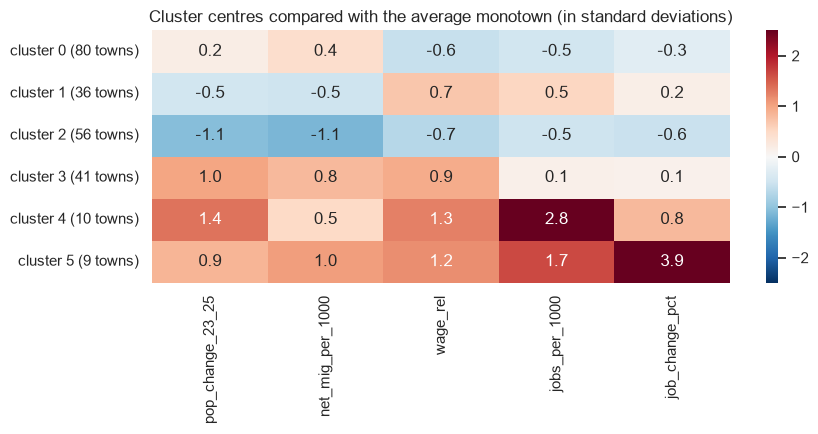

In [12]:
centres = pd.DataFrame(km.cluster_centers_, columns=CLUSTER_VARS)
centres.index = [f"cluster {c} ({n} towns)" for c, n in zip(centres.index, np.bincount(km.labels_))]

plt.figure(figsize=(9, 4.5))
sns.heatmap(centres, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2.5, vmax=2.5)
plt.title("Cluster centres compared with the average monotown (in standard deviations)")
plt.tight_layout()
plt.show()

## Six monotown types

| cluster | type | pattern compared with the average monotown |
|---|---|---|
| 0 | Slow decline, thin job base | demography close to average, economy below: fewer jobs, lower wages, jobs lost |
| 2 | Depopulating towns | below average on everything, migration far below: the most distressed type |
| 3 | Stable industrial centres | above average on everything: good wages, people stay |
| 1 | Working towns losing people | economy above average (wages, jobs), demography below: people leave despite jobs |
| 4 | High-employment strongholds | jobs per resident far above average, around one dominant employer (northern mining, shipbuilding, steel, titanium) |
| 5 | Job-boom towns | job change far above average: rapid growth since 2017, mostly defence plants and the Alabuga economic zone |

The table below shows medians of the original (uncapped) values. "Typical towns" are the four closest to each cluster centre.

In [13]:
# names are tied to cluster numbers, which are fixed by random_state; re-check them if the data changes
NAMES = {
    0: "Slow decline, thin job base",
    1: "Working towns losing people",
    2: "Depopulating towns",
    3: "Stable industrial centres",
    4: "High-employment strongholds",
    5: "Job-boom towns",
}
df["type"] = df["cluster"].map(NAMES)

# typical towns: the four closest to their cluster centre
df["dist_to_centre"] = km.transform(X)[np.arange(len(df)), df["cluster"]]
typical = (df.sort_values("dist_to_centre")
             .groupby("cluster")["name_en"].apply(lambda s: ", ".join(s.head(4))))

groups = df.groupby("cluster")
profile = groups[CLUSTER_VARS].median().round(2)
profile.insert(0, "type", pd.Series(NAMES))
profile.insert(1, "towns", groups.size())
profile["typical towns"] = typical
profile["Slantsy"] = groups["number"].apply(lambda s: "yes" if SLANTSY in s.values else "")
profile.sort_values("towns", ascending=False)

,type,towns,pop_change_23_25,net_mig_per_1000,wage_rel,jobs_per_1000,job_change_pct,typical towns,Slantsy
cluster,,,,,,,,,
0,"Slow decline, thin job base",80,-1.73,0.49,1.00,189.74,-10.85,"Stepnoye Ozero, Lysva, Osinniki, Rossosh",yes
2,Depopulating towns,56,-3.07,-7.00,0.99,189.29,-15.23,"Kataysk, Kolchugino, Gus-Khrustalny, Tashtagol",
3,Stable industrial centres,41,-0.96,1.69,1.29,255.87,-5.18,"Novokuznetsk, Volodarsk, Miass, Linyovo",
1,Working towns losing people,36,-2.50,-3.67,1.24,284.07,-5.22,"Rybinsk, Sarapul, Asha, Kozmodemyansk",
4,High-employment strongholds,10,-0.37,0.52,1.34,487.21,9.66,"Severodvinsk, Krasnobrodsky, Nizhny Kuranakh, ...",
5,Job-boom towns,9,-0.54,2.64,1.30,343.28,64.66,"Kotovsk, Verkhnyaya Tura, Neryungri, Aleksin",


In [14]:
# reference: all towns of each type
for t, group in df.groupby("type"):
    print(f"--- {t} ({len(group)} towns) ---")
    print(", ".join(group["name_en"]))
    print()

--- Depopulating towns (56 towns) ---
Onega, Petrovsk-Zabaykalsky, Anzhero-Sudzhensk, Prokopyevsk, Demyanovo, Manturovo, Parfino, Gorny, Aleksandrovsk, Nytva, Pechory, Pudozh, Zheshart, Inta, Zverevo, Skopin, Firovo, Verkhny Ufaley, Nyazepetrovsk, Ust-Katav, Plesetsk, Oktyabrsky, Gorokhovets, Vyazniki, Melenki, Sobinka, Gus-Khrustalny, Kolchugino, Verkh-Usugli, Aginskoye, Borzya, Kolobovo, Navoloki, Savino, Vichuga, Usolye-Sibirskoye, Tashtagol, Krasnaya Polyana, Zaozyorny, Vargashi, Dalmatovo, Nikel, Okulovka, Yasny, Bolkhov, Gornozavodsk, Vostok, Yaroslavsky, Kondopoga, Pitkyaranta, Kanash, Gavrilov-Yam, Kirs, Kataysk, Mokshan, Belyov

--- High-employment strongholds (10 towns) ---
Severodvinsk, Krasnobrodsky, Kirovsk, Udachny, Aykhal, Mirny, Norilsk, Vyksa, Nizhny Kuranakh, Verkhnyaya Salda

--- Job-boom towns (9 towns) ---
Seltso, Borovsk, Neryungri, Yelabuga, Aleksin, Yantarny, Zelenodolsk, Verkhnyaya Tura, Kotovsk

--- Slow decline, thin job base (80 towns) ---
Raychikhinsk, Bery

## Describing the types

So far the types were described with the five variables that built them, which is partly circular. Here they are compared with information the clustering did not use.

**Official monotown category** (Order 469-р): category 1 = the most difficult socio-economic situation, category 2 = risk of deterioration, category 3 = stable situation. The data-driven types agree with this official rating. Depopulating towns have the highest share of category 1 (36%). The three stronger types have the highest shares of category 3 (39-44%), and the strongholds and job-boom towns have no category 1 towns at all.

**Industry share** (mining and manufacturing) was planned as a third description, but Rosstat publishes both sections for only 40 of 232 towns, because data on dominant employers are confidential. Medians based on 2-13 towns per type are not reliable, so this variable is left out.

**Spread within types** (box plots; dashed line = median of all towns, red dot = Slantsy): each type is clearly separated on the variable it is named after, but types overlap on the others, as the silhouette of 0.24 suggests. Slantsy sits at the edge of its type: near the bottom on population change and jobs per 1,000, near the top on migration and job retention.

The cluster membership is saved to `data/processed/clusters.csv` for the maps in notebook 05.

In [18]:
#official monotown category (Order 469-р) within each type, % of towns
order = df["type"].value_counts().index        # largest type first
cat = pd.crosstab(df["type"], df["category"], normalize="index").mul(100).round(0)
cat.columns = [f"category {c}, %" for c in cat.columns]
cat.insert(0, "towns", df["type"].value_counts())
cat.loc[order]

,towns,"category 1, %","category 2, %","category 3, %"
type,,,,
"Slow decline, thin job base",80,12.0,62.0,25.0
Depopulating towns,56,36.0,57.0,7.0
Stable industrial centres,41,7.0,54.0,39.0
Working towns losing people,36,22.0,47.0,31.0
High-employment strongholds,10,0.0,60.0,40.0
Job-boom towns,9,0.0,56.0,44.0


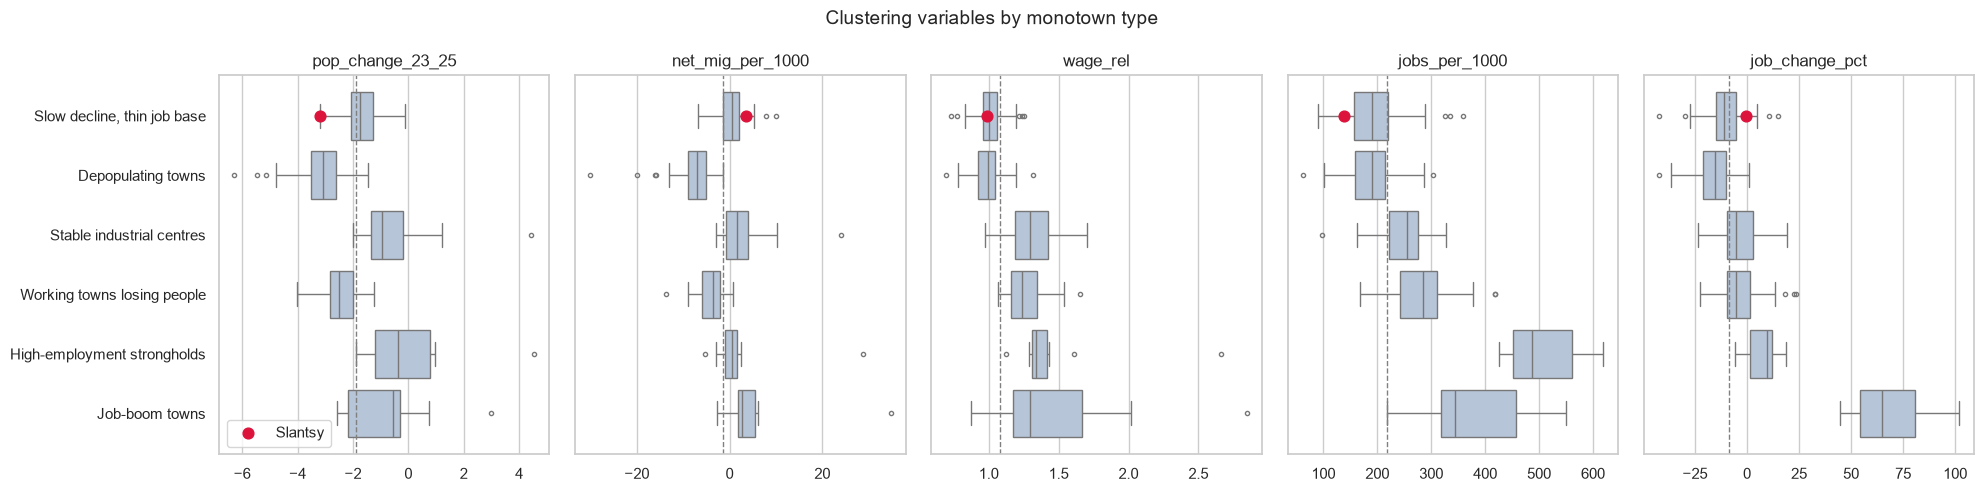

In [19]:
#each variable by type, original values; dashed line = median of all towns, red dot = Slantsy
slantsy_row = df[df["number"] == SLANTSY].iloc[0]
slantsy_pos = list(order).index(slantsy_row["type"])

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=True)
for ax, var in zip(axes, CLUSTER_VARS):
    sns.boxplot(data=df, x=var, y="type", order=order, ax=ax,
                color="lightsteelblue", fliersize=3)
    ax.axvline(df[var].median(), color="grey", linestyle="--", linewidth=1)
    ax.scatter(slantsy_row[var], slantsy_pos, color="crimson", s=60, zorder=3, label="Slantsy")
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[0].legend(loc="lower left")
plt.suptitle("Clustering variables by monotown type", fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
#cluster membership for notebook 05
clusters = df[["number", "name_en", "region_en", "oktmo", "cluster", "type"]]
clusters.to_csv("../data/processed/clusters.csv", index=False)
print(clusters.shape)

(232, 6)
